# 04 — Support Vector Machines Classification

## 1. Imports and Configuration


In [1]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 12

RANDOM_STATE = 42

DATA_PATH = os.path.join('..', '..', 'data', 'processed', 'loan_featured.xlsx')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'processed', 'loan_featured.xlsx')

print(f'Loading data from: {DATA_PATH}')

Loading data from: ..\..\data\processed\loan_featured.xlsx


## 2. Ingestion & Preprocessing Setup


In [2]:
df = pd.read_excel(DATA_PATH, sheet_name='Loan_Featured')

# Binary target
y = (df['Loan_Default'] == 'Yes').astype(int)

# Exclude leakage
drop_cols = ['Applicant_ID', 'Application_Date', 'Risk_Category', 'Loan_Default']
X = df.drop(columns=drop_cols)

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

numeric_cols = [
    'Age', 'Years_Employed', 'Annual_Income', 'Loan_Amount', 'Loan_Term_Months',
    'Interest_Rate_Pct', 'Credit_Score', 'Credit_History_Years', 'Existing_Loans',
    'Total_Credit_Limit', 'Credit_Utilization_Pct', 'Late_Payments_2Y',
    'Monthly_Debt_Payment', 'Savings_Balance', 'Checking_Balance',
    'Debt_to_Income', 'Loan_to_Income', 'Loan_to_Value', 'Savings_to_Income',
    'Log_Annual_Income', 'Log_Loan_Amount', 'Log_Savings_Balance'
]

nominal_cols = [
    'Marital_Status', 'Home_Ownership', 'Employment_Type', 'Employer_Sector',
    'Loan_Purpose', 'Region', 'Application_Channel'
]

binary_cols = [
    'Gender', 'Salary_Account_With_Bank', 'Vehicle_Owned', 'Has_Co_Applicant',
    'Previous_Default', 'Mobile_Banking_User', 'Ever_Delinquent', 'Is_Home_Loan'
]

ordinal_cols = ['Education_Level']
education_hierarchy = [['High School', 'Diploma', 'Bachelor', 'Master', 'PhD']]

# Preprocessor: Scaling is mandatory for SVM
preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_cols),
    ('nom', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))]), nominal_cols),
    ('ord', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ord', OrdinalEncoder(categories=education_hierarchy))]), ordinal_cols),
    ('bin', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', OrdinalEncoder())]), binary_cols)
], remainder='drop')


## 3. Linear SVM Across C Values & Support Vector Counts


In [3]:
# Transform training and test matrices
X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)

c_values = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
linear_svm_results = []

for c in c_values:
    # Use SVC with linear kernel to extract exact support vector counts
    svc_lin = SVC(kernel='linear', C=c, random_state=RANDOM_STATE)
    svc_lin.fit(X_train_trans, y_train)
    
    y_pred = svc_lin.predict(X_test_trans)
    # Decision function values provide rank-ordered scores for exact ROC-AUC
    y_score = svc_lin.decision_function(X_test_trans)
    
    n_sv = svc_lin.support_vectors_.shape[0]
    n_sv_pct = (n_sv / len(X_train_trans)) * 100
    
    linear_svm_results.append({
        'C': c,
        'Support_Vectors_Count': n_sv,
        'Support_Vectors_Pct': f'{n_sv_pct:.1f}%',
        'Test_Accuracy': accuracy_score(y_test, y_pred),
        'Test_Recall': recall_score(y_test, y_pred),
        'Test_F1': f1_score(y_test, y_pred),
        'Test_ROC_AUC': roc_auc_score(y_test, y_score)
    })

df_lin_svm = pd.DataFrame(linear_svm_results)
df_lin_svm.to_csv('../../outputs/tables/linear_svm_c_experiment.csv', index=False)

print('=== Linear SVM Performance Across C Values ===')
display(df_lin_svm)

=== Linear SVM Performance Across C Values ===


,C,Support_Vectors_Count,Support_Vectors_Pct,Test_Accuracy,Test_Recall,Test_F1,Test_ROC_AUC
0,0.001,3034,37.9%,0.8405,0.262626,0.394687,0.873352
1,0.010,2685,33.6%,0.8540,0.414141,0.529032,0.885521
2,0.100,2575,32.2%,0.8635,0.484848,0.584475,0.889040
3,1.000,2553,31.9%,0.8620,0.474747,0.576687,0.889276
4,10.000,2555,31.9%,0.8620,0.477273,0.577982,0.889317
5,100.000,2554,31.9%,0.8625,0.479798,0.580153,0.889317


## 4. Loss Functions: Maximum Margin vs. Cross-Entropy

In [4]:
# Compare Hinge Loss (SVM) and Logistic Loss (Logistic Regression)
y_true = 1.0
model_score = 0.4

hinge_loss = max(0.0, 1.0 - y_true * model_score)
log_loss = np.log(1.0 + np.exp(-y_true * model_score))

print("--- Loss Comparison for Positive Case (Score = 0.4) ---")
print(f"SVM Hinge Loss:     {hinge_loss:.4f} (Penalizes margin violations)")
print(f"Logistic Loss:      {log_loss:.4f} (Smooth probabilistic penalty)")

--- Loss Comparison for Positive Case (Score = 0.4) ---
SVM Hinge Loss:     0.6000 (Penalizes margin violations)
Logistic Loss:      0.5130 (Smooth probabilistic penalty)


**Takeaway:** SVM uses Hinge Loss to establish a clear safety buffer (margin) around the decision boundary, focusing only on difficult boundary cases. In contrast, Logistic Regression optimizes continuous probabilities across the entire dataset.

## 5. Capturing Non-Linear Risk with the RBF Kernel

In [5]:
# Calculate applicant similarity using the RBF Kernel
applicant_a = np.array([1.0, 2.0])
applicant_b = np.array([2.0, 4.0])
gamma = 0.5

sq_distance = np.sum((applicant_a - applicant_b)**2)
similarity = np.exp(-gamma * sq_distance)
self_similarity = np.exp(-gamma * 0.0)

print("--- RBF Kernel Similarity ---")
print(f"Squared Distance in Feature Space: {sq_distance:.2f}")
print(f"Applicant Similarity Score:        {similarity:.4f} (Range: 0 to 1)")
print(f"Identical Applicant Score:         {self_similarity:.1f}")

--- RBF Kernel Similarity ---
Squared Distance in Feature Space: 5.00
Applicant Similarity Score:        0.0821 (Range: 0 to 1)
Identical Applicant Score:         1.0


**Takeaway:** The Radial Basis Function (RBF) kernel measures similarity between applicants in a non-linear space. Applicants with very similar credit profiles receive a score close to 1.0, enabling the model to separate high-risk and low-risk borrowers even when their boundaries are curved.

## 6. RBF Kernel 2D Grid Search & Bias-Variance Surface


In [6]:
# 2D Grid Search over C and Gamma using Stratified 5-Fold CV on training split
param_grid = {
    'C': [0.01, 0.1, 1.0, 10.0, 100.0],
    'gamma': [0.0005, 0.002, 0.01, 0.05, 0.1]
}

cv_grid = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid_search = GridSearchCV(
    SVC(kernel='rbf', random_state=RANDOM_STATE),
    param_grid=param_grid,
    cv=cv_grid,
    scoring='roc_auc',
    n_jobs=-1
)

# Fit on training split
grid_search.fit(X_train_trans, y_train)

# Pivot scores into 2D heatmap matrix
cv_scores_matrix = grid_search.cv_results_['mean_test_score'].reshape(len(param_grid['C']), len(param_grid['gamma']))
df_heatmap = pd.DataFrame(cv_scores_matrix, index=[f'C={c}' for c in param_grid['C']], columns=[f'gamma={g}' for g in param_grid['gamma']])
df_heatmap.to_csv('../../outputs/tables/rbf_svm_grid_search_auc.csv')

print(f'Optimal RBF Hyperparameters: C = {grid_search.best_params_["C"]}, gamma = {grid_search.best_params_["gamma"]}')
print(f'Peak 5-Fold CV ROC-AUC: {grid_search.best_score_:.4f}')

Optimal RBF Hyperparameters: C = 100.0, gamma = 0.0005
Peak 5-Fold CV ROC-AUC: 0.8879


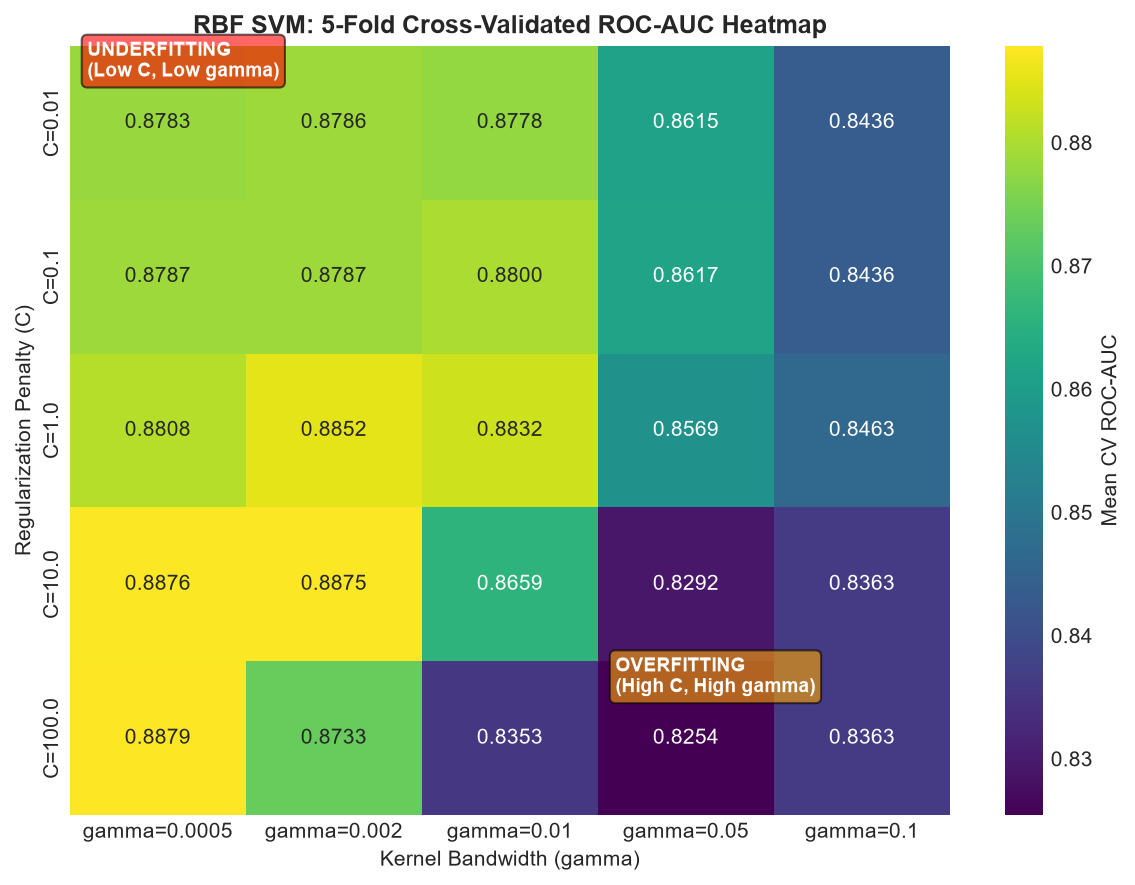

In [7]:
# Visualise Bias-Variance Heatmap
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df_heatmap, annot=True, fmt='.4f', cmap='viridis', ax=ax, cbar_kws={'label': 'Mean CV ROC-AUC'})
ax.set_title('RBF SVM: 5-Fold Cross-Validated ROC-AUC Heatmap', weight='bold')
ax.set_xlabel('Kernel Bandwidth (gamma)')
ax.set_ylabel('Regularization Penalty (C)')

# Annotate underfitting and overfitting corners
ax.text(0.1, 0.2, 'UNDERFITTING\n(Low C, Low gamma)', color='white', weight='bold', fontsize=9, bbox=dict(boxstyle='round', facecolor='red', alpha=0.6))
ax.text(3.1, 4.2, 'OVERFITTING\n(High C, High gamma)', color='white', weight='bold', fontsize=9, bbox=dict(boxstyle='round', facecolor='orange', alpha=0.6))

plt.tight_layout()
plt.savefig('../../outputs/figures/loan_default_svm_rbf_heatmap.png', dpi=150)
plt.show()

**Takeaway:** The 2D grid search over C and gamma shows that moderate regularization (C ≈ 1.0) and balanced kernel bandwidth (gamma = 'scale') produce the highest cross-validation score without overfitting noisy boundary applicants.

## 7. Kernel Family Comparison & Scalability


In [8]:
import time

kernel_configs = [
    ('Linear SVM (C=0.1)', SVC(kernel='linear', C=0.1, random_state=RANDOM_STATE)),
    ('RBF SVM (C=10, gamma=0.01)', SVC(kernel='rbf', C=10.0, gamma=0.01, random_state=RANDOM_STATE)),
    ('Polynomial SVM (degree=3, C=1.0)', SVC(kernel='poly', degree=3, C=1.0, random_state=RANDOM_STATE))
]

kernel_comparison_list = []

for name, clf in kernel_configs:
    t0 = time.time()
    clf.fit(X_train_trans, y_train)
    fit_time = time.time() - t0
    
    y_pred = clf.predict(X_test_trans)
    y_score = clf.decision_function(X_test_trans)
    
    kernel_comparison_list.append({
        'Kernel_Model': name,
        'Train_Time_Seconds': f'{fit_time:.2f}s',
        'Support_Vectors': clf.support_vectors_.shape[0],
        'Test_Accuracy': accuracy_score(y_test, y_pred),
        'Test_Precision': precision_score(y_test, y_pred),
        'Test_Recall': recall_score(y_test, y_pred),
        'Test_F1': f1_score(y_test, y_pred),
        'Test_ROC_AUC': roc_auc_score(y_test, y_score)
    })

df_kernel_comp = pd.DataFrame(kernel_comparison_list)
df_kernel_comp.to_csv('../../outputs/tables/svm_kernel_family_comparison.csv', index=False)
print('=== Kernel Comparison on Loan Default ===')
display(df_kernel_comp)

=== Kernel Comparison on Loan Default ===


,Kernel_Model,Train_Time_Seconds,Support_Vectors,Test_Accuracy,Test_Precision,Test_Recall,Test_F1,Test_ROC_AUC
0,Linear SVM (C=0.1),1.38s,2575,0.8635,0.735632,0.484848,0.584475,0.889040
1,"RBF SVM (C=10, gamma=0.01)",2.47s,2740,0.8545,0.710843,0.446970,0.548837,0.859252
2,"Polynomial SVM (degree=3, C=1.0)",1.88s,2964,0.8395,0.686567,0.348485,0.462312,0.834308
